In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "Cleaned" / "city_day_clean.csv", parse_dates=["Date"])
POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
BUCKET_ORDER = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

sns.set_theme(style="whitegrid")
print(df.shape)
df.head()

(24801, 23) 


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,...,AQI,AQI_Bucket,Year,Month,Day,Weekday,Is_Weekend,Season,Is_Winter,Is_Diwali_Period
0,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,...,209.0,Poor,2015,1,29,3,0,Winter,1,0
1,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,...,328.0,Very Poor,2015,1,30,4,0,Winter,1,0
2,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,...,514.0,Severe,2015,1,31,5,1,Winter,1,0
3,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,...,782.0,Severe,2015,2,1,6,1,Winter,1,0
4,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,...,914.0,Severe,2015,2,2,0,0,Winter,1,0


Setup and load data

In [2]:
df[POLL + ["AQI"]].describe().round(1)

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
count,24172.0,17764.0,24463.0,24459.0,22993.0,18314.0,24405.0,24245.0,24043.0,21315.0,19024.0,24801.0
mean,67.5,118.5,17.6,29.0,32.3,23.8,2.3,14.4,34.9,3.5,9.5,166.6
std,63.1,89.5,22.4,24.6,30.7,25.9,7.1,17.4,21.7,16.0,20.9,140.8
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0
25%,29.0,56.8,5.7,11.9,13.1,9.0,0.6,5.7,19.2,0.2,1.0,81.0
50%,48.8,96.2,9.9,22.1,23.7,16.3,0.9,9.2,31.2,1.3,3.6,118.0
75%,80.9,150.2,20.0,38.2,40.2,30.4,1.5,15.1,46.1,3.3,10.2,208.0
max,914.9,917.1,390.7,362.2,378.2,352.9,175.8,186.1,257.7,455.0,454.8,2049.0


Summary statistics

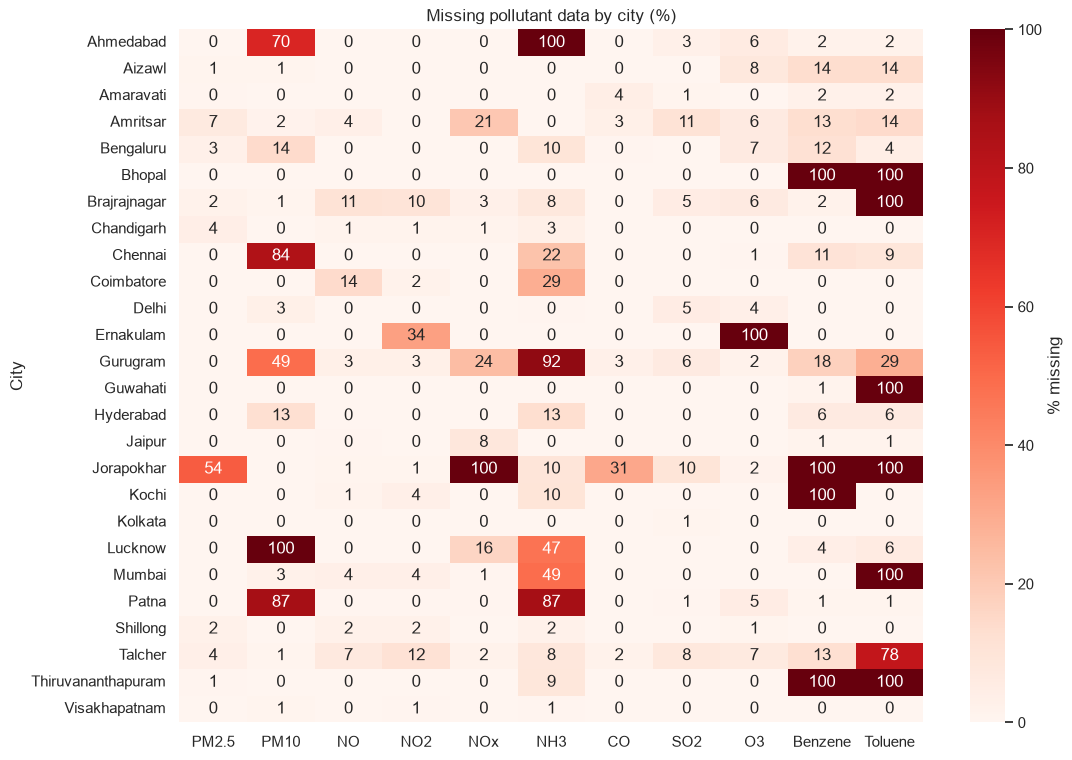

In [3]:
missing_pct = df[POLL].isna().groupby(df["City"]).mean() * 100

plt.figure(figsize=(12, 9))
sns.heatmap(missing_pct, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("Missing pollutant data by city (%)")
plt.savefig(OUT / "01_missing_by_city.png", dpi=150, bbox_inches="tight")
plt.show()

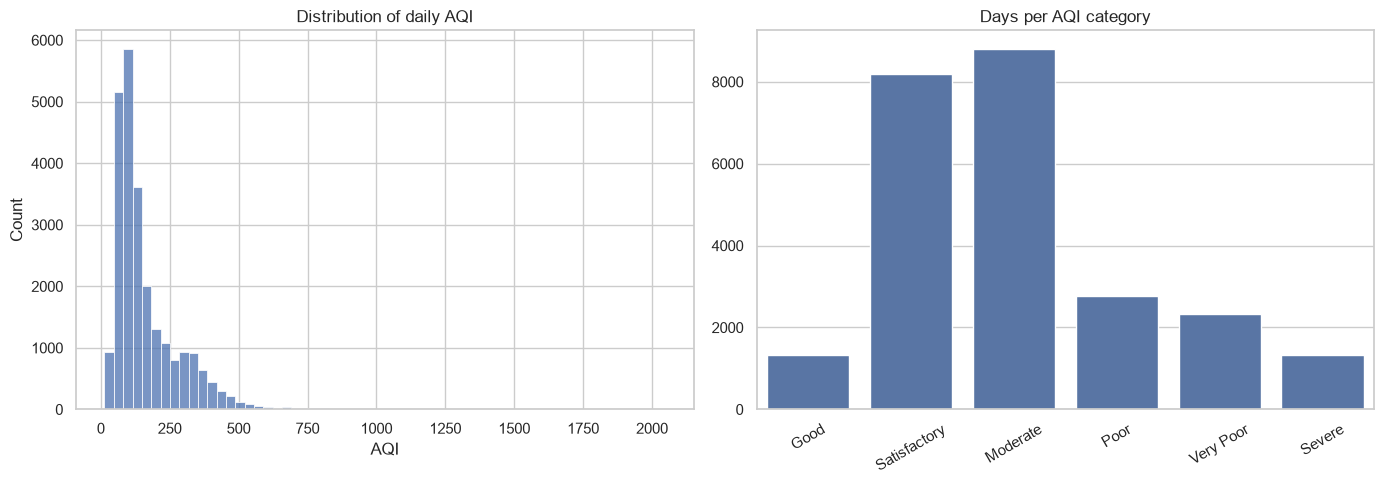

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["AQI"], bins=60, ax=axes[0])
axes[0].set_title("Distribution of daily AQI")

counts = df["AQI_Bucket"].value_counts().reindex(BUCKET_ORDER)
sns.barplot(x=counts.index, y=counts.values, ax=axes[1])
axes[1].set_title("Days per AQI category")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(OUT / "02_aqi_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

AQI distribution and category counts

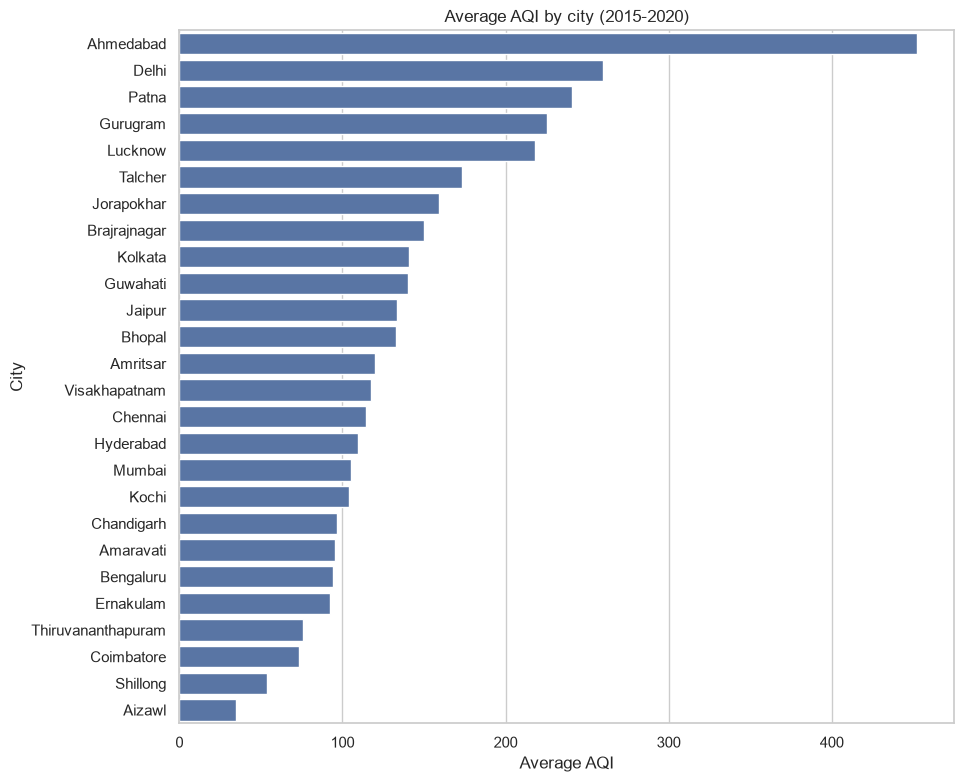

In [5]:
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 9))
sns.barplot(x=city_aqi.values, y=city_aqi.index)
plt.xlabel("Average AQI")
plt.title("Average AQI by city (2015-2020)")
plt.savefig(OUT / "03_city_avg_aqi.png", dpi=150, bbox_inches="tight")
plt.show()

City-wise average AQI

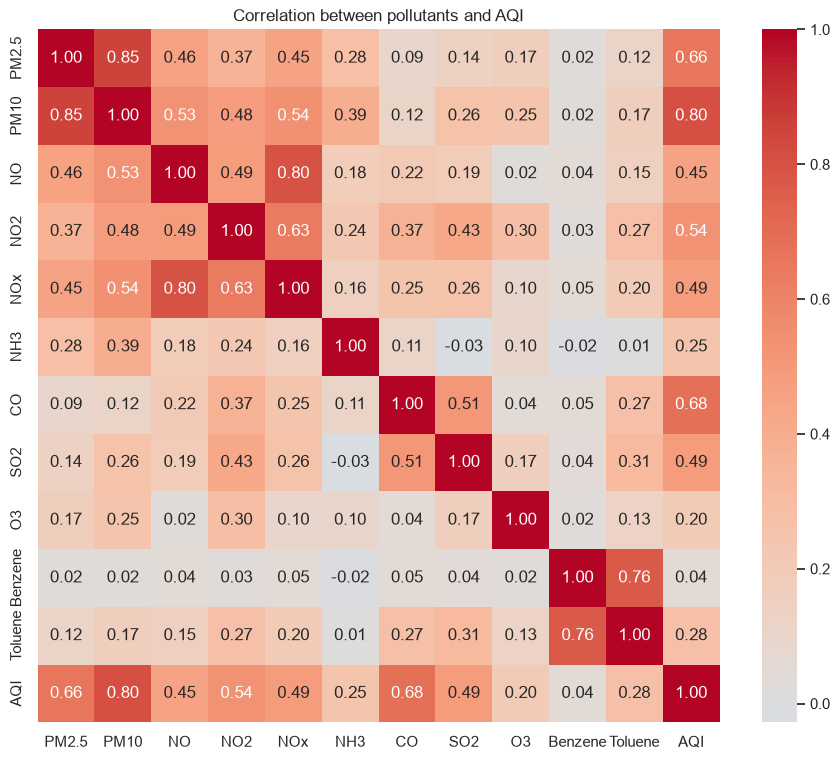

In [6]:
corr = df[POLL + ["AQI"]].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between pollutants and AQI")
plt.savefig(OUT / "04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Pollutant correlations

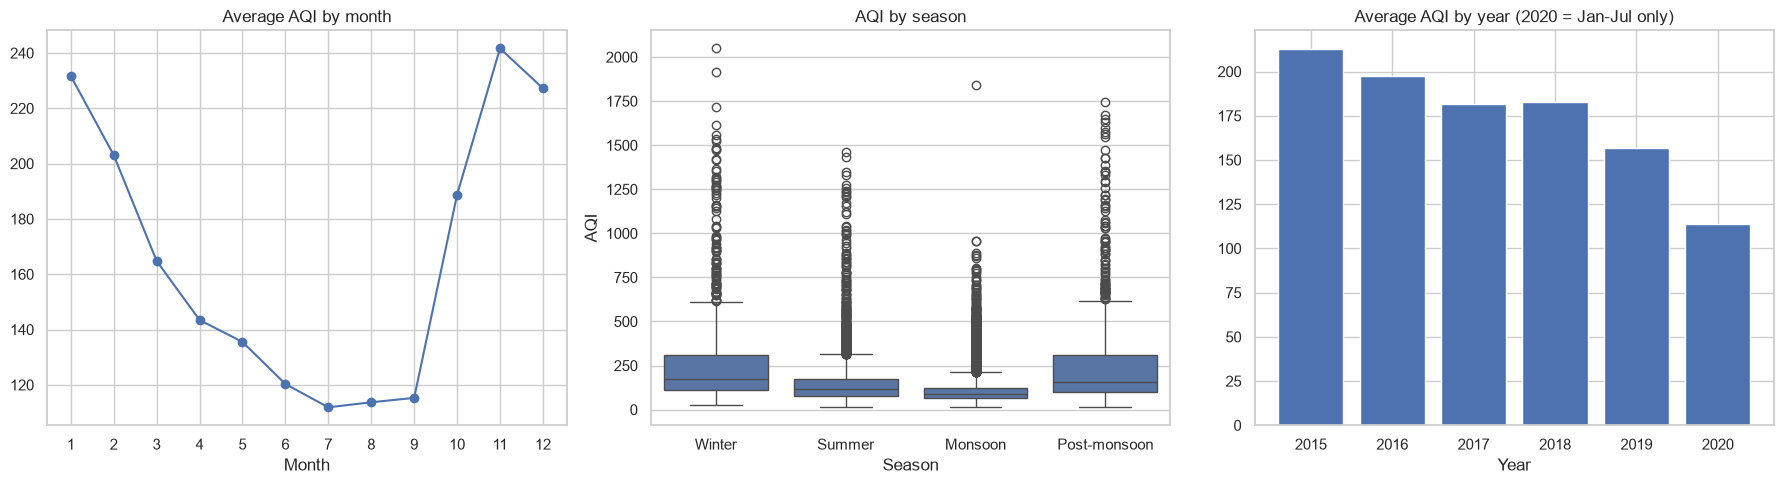

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

monthly = df.groupby("Month")["AQI"].mean()
axes[0].plot(monthly.index, monthly.values, marker="o")
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Average AQI by month")
axes[0].set_xlabel("Month")

season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
sns.boxplot(data=df, x="Season", y="AQI", order=season_order, ax=axes[1])
axes[1].set_title("AQI by season")

yearly = df.groupby("Year")["AQI"].mean()
axes[2].bar(yearly.index.astype(str), yearly.values)
axes[2].set_title("Average AQI by year (2020 = Jan-Jul only)")
axes[2].set_xlabel("Year")

plt.tight_layout()
plt.savefig(OUT / "05_time_trends.png", dpi=150, bbox_inches="tight")
plt.show()

Monthly, seasonal and yearly trends

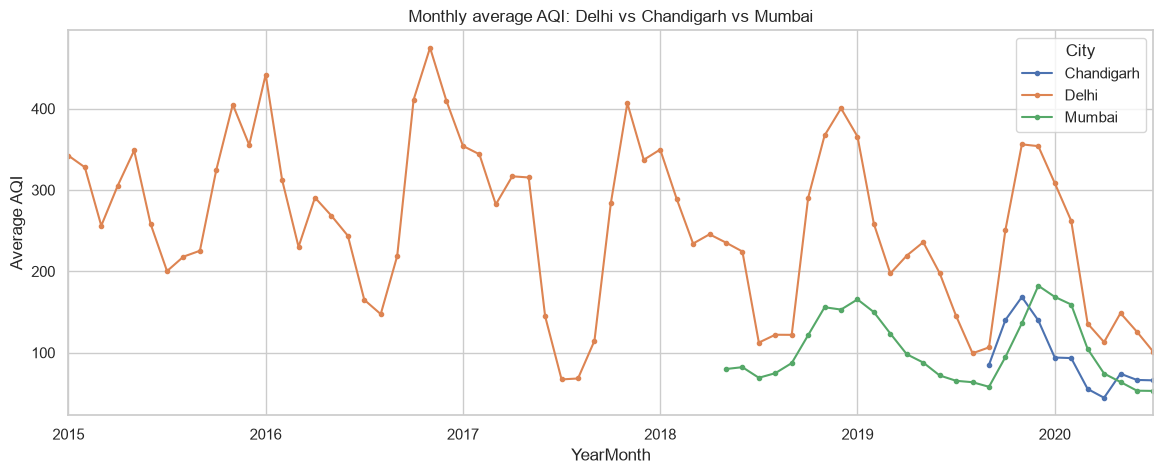

In [8]:
cities = ["Delhi", "Chandigarh", "Mumbai"]
sub = df[df["City"].isin(cities)].copy()
sub["YearMonth"] = sub["Date"].dt.to_period("M").dt.to_timestamp()
monthly_city = sub.groupby(["YearMonth", "City"])["AQI"].mean().unstack()

monthly_city.plot(figsize=(14, 5), marker=".")
plt.ylabel("Average AQI")
plt.title("Monthly average AQI: Delhi vs Chandigarh vs Mumbai")
plt.savefig(OUT / "06_city_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Delhi, Chandigarh and Mumbai over time

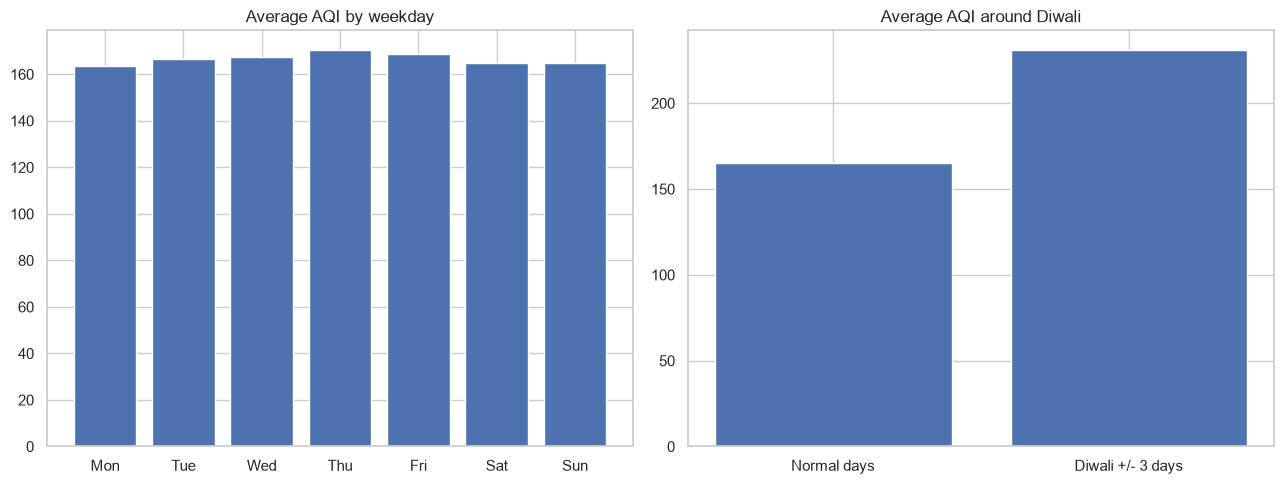

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

weekday = df.groupby("Weekday")["AQI"].mean()
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday.values)
axes[0].set_title("Average AQI by weekday")

diwali = df.groupby("Is_Diwali_Period")["AQI"].mean()
axes[1].bar(["Normal days", "Diwali +/- 3 days"], diwali.values)
axes[1].set_title("Average AQI around Diwali")

plt.tight_layout()
plt.savefig(OUT / "07_weekday_diwali.png", dpi=150, bbox_inches="tight")
plt.show()

Weekday and Diwali effects

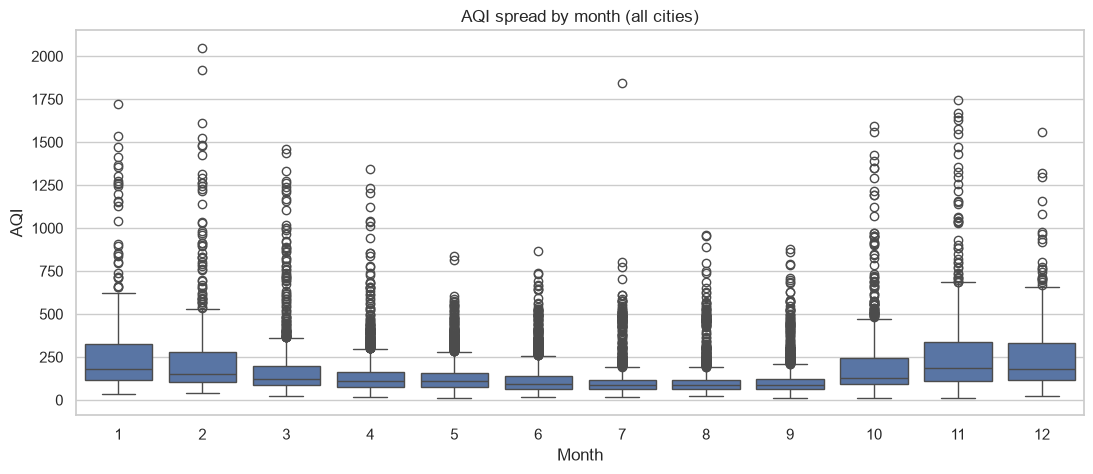

In [10]:
plt.figure(figsize=(13, 5))
sns.boxplot(data=df, x="Month", y="AQI")
plt.title("AQI spread by month (all cities)")
plt.savefig(OUT / "08_monthly_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

Monthly AQI boxplot

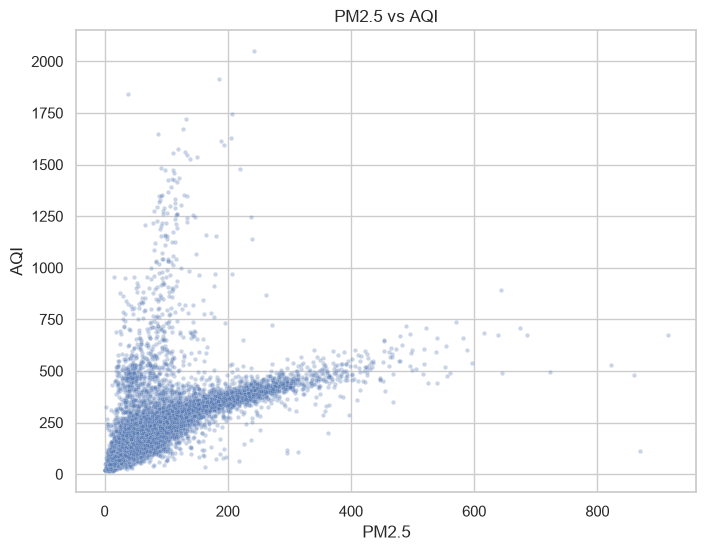

In [11]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="PM2.5", y="AQI", alpha=0.3, s=10)
plt.title("PM2.5 vs AQI")
plt.savefig(OUT / "09_pm25_vs_aqi.png", dpi=150, bbox_inches="tight")
plt.show()

PM2.5 vs AQI scatter 